# CASO PRÁCTICO
## Análisis De Ventas Y Comportamiento De Clientes Con Estadística E IA

## Situación problemática

La empresa Comercial TechPerú S.A.C. vende productos tecnológicos y registra contactos,
cotizaciones, compras y entregas. La gerencia requiere analizar sus operaciones, evaluar la
puntualidad de las entregas y descubrir segmentos de clientes. Como analista de datos,
desarrollarás un informe reproducible en Google Colab con base en un archivo CSV de 1 000
registros.

## Objetivo

Aplicar estadística descriptiva, probabilidad, distribución binomial, contraste de hipótesis y algoritmos supervisados y no supervisados para proponer decisiones comerciales
sustentadas en datos.


### Antes de ejecutar en Google Colab

Abre este notebook en Colab y sube **Caso_Practico_TechPeru.csv** desde el panel **Archivos** de la izquierda, conservando ese nombre. Luego selecciona **Entorno de ejecución → Ejecutar todas**. El CSV debe estar en la carpeta de trabajo de Colab; si se reinicia o cambia la sesión, puede ser necesario subirlo otra vez.

In [1]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Actividad 1: Exploración y estadística descriptiva

Cargar el CSV y mostrar 10 registros.

Identificar tipos de datos, valores ausentes y categorías.

Para las compras efectivas, calcular media, mediana, varianza y desviación estándar de venta_soles.

Construir histograma de ventas y tabla de frecuencias por categoria_producto.

Interpretar los resultados.

In [2]:
# Cargar el CSV y mostrar 10 registros.
df = pd.read_csv("Caso_Practico_TechPeru.csv")
df.head(10)

,id_cliente,fecha_contacto,edad,canal,categoria_producto,visitas_web,contactos_comerciales,precio_cotizado_soles,descuento_porcentaje,realizo_compra,venta_soles,dias_entrega,entrega_puntual,satisfaccion_1_5
0,C0001,2026-08-07,37,WhatsApp,Laptop,3,4,2762.15,10,0,0.00,NaN,NaN,NaN
1,C0002,2026-07-19,49,Tienda,Accesorios,6,4,218.35,15,1,185.60,1.0,1.0,4.0
2,C0003,2026-07-28,62,Web,Smartphone,6,4,1215.22,5,1,1154.46,7.0,1.0,3.0
3,C0004,2026-09-02,65,Web,Smartphone,6,2,673.87,5,1,640.18,2.0,0.0,4.0
4,C0005,2026-08-14,42,Web,Smartphone,5,3,1192.92,0,0,0.00,NaN,NaN,NaN
5,C0006,2026-07-27,27,Tienda,Tablet,3,5,1120.55,0,1,1120.55,5.0,0.0,2.0
6,C0007,2026-08-26,27,WhatsApp,Monitor,3,5,646.83,0,1,646.83,1.0,1.0,3.0
7,C0008,2026-07-23,64,Tienda,Laptop,7,2,3463.14,0,1,3463.14,8.0,1.0,4.0
8,C0009,2026-08-28,61,WhatsApp,Accesorios,8,5,131.96,0,1,131.96,2.0,1.0,4.0
9,C0010,2026-09-22,63,Tienda,Smartphone,4,7,1107.89,5,1,1052.50,8.0,1.0,4.0


In [3]:
# Identificar tipos de datos
df.dtypes

id_cliente                object
fecha_contacto            object
edad                       int64
canal                     object
categoria_producto        object
visitas_web                int64
contactos_comerciales      int64
precio_cotizado_soles    float64
descuento_porcentaje       int64
realizo_compra             int64
venta_soles              float64
dias_entrega             float64
entrega_puntual          float64
satisfaccion_1_5         float64
dtype: object

In [4]:
# Identificar valores ausentes
print(df.isnull().sum())

id_cliente                 0
fecha_contacto             0
edad                       0
canal                      0
categoria_producto         0
visitas_web                0
contactos_comerciales      0
precio_cotizado_soles      0
descuento_porcentaje       0
realizo_compra             0
venta_soles                0
dias_entrega             237
entrega_puntual          237
satisfaccion_1_5         237
dtype: int64


In [5]:
# Identificar categorias
print("Categorías de producto:", df["categoria_producto"].unique())
print("Canales comerciales:", df["canal"].unique())

Categorías de producto: ['Laptop' 'Accesorios' 'Smartphone' 'Tablet' 'Monitor']
Canales comerciales: ['WhatsApp' 'Tienda' 'Web']


Hay **1000 contactos**. Las columnas numéricas incluyen la edad, las visitas, los contactos y los montos; el identificador, la fecha y las categorías se cargan como texto. No necesitamos convertir la fecha para estas actividades.

Las categorías de producto son Laptop, Accesorios, Smartphone, Tablet y Monitor. Los canales son WhatsApp, Tienda y Web.

Hay **237 datos ausentes** en cada una de las columnas de entrega y satisfacción. Corresponden a los contactos que no compraron, por lo que no se reemplazan por cero ni se eliminan esos contactos del análisis de conversión. Las variables que usaremos para los modelos no tienen valores ausentes.

In [6]:
# Para las compras efectivas,
# calcular media, mediana, varianza y desviación estándar de venta_soles.

# definir compras realizadas, en el csv hay valor de
# 0 para los que no realizaron compra
# 1 para los que realizaron compras
compras = df[df["realizo_compra"] == 1]

# calcular media
media = compras["venta_soles"].mean()

# calcular mediana
mediana = compras["venta_soles"].median()

# calcular varianza
varianza = compras["venta_soles"].var()

# desviacion estandar
desviacion = compras["venta_soles"].std()

# mostrar
print("Compras efectivas:", len(compras))
print("Media: S/", round(media, 2))
print("Mediana: S/", round(mediana, 2))
print("Varianza (soles²):", round(varianza, 2))
print("Desviación estándar: S/", round(desviacion, 2))

Compras efectivas: 763
Media: S/ 913.95
Mediana: S/ 798.36
Varianza (soles²): 591538.57
Desviación estándar: S/ 769.12


**Interpretación de las estadísticas**

Se realizaron **763 compras**. La media es **S/ 913,95**: ese es el monto promedio de una compra. La mediana es **S/ 798,36**: la mitad de las compras tiene un monto menor o igual a ese valor y la otra mitad, mayor o igual.

La desviación estándar es **S/ 769,12**, lo que indica que los montos varían bastante alrededor de la media. La varianza es **591 538,57 soles²**; también mide la dispersión, pero está en unidades al cuadrado. Se usaron la varianza y la desviación estándar muestrales que calcula pandas por defecto.

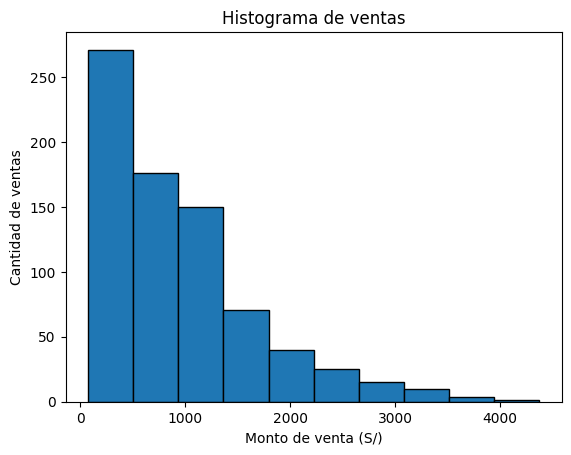

In [7]:
# Construir histograma de ventas
plt.hist(compras["venta_soles"], bins=10, edgecolor="black")

plt.title("Histograma de ventas")
plt.xlabel("Monto de venta (S/)")
plt.ylabel("Cantidad de ventas")

plt.show()

**Interpretación:** se puede observar que hay más compras de montos bajos y menos compras de montos altos.

**Cómo se lee el gráfico:** el eje horizontal muestra intervalos del monto vendido en soles y el eje vertical indica cuántas compras hay en cada intervalo.

**Qué significan los resultados:** algunas compras altas alargan el gráfico hacia la derecha y hacen que la media de S/ 913,95 sea mayor que la mediana de S/ 798,36. Los montos no se concentran alrededor de un único valor.

In [8]:
# Construir tabla de frecuencias por categoria_producto.
frecuencia = df["categoria_producto"].value_counts()
frecuencia

categoria_producto
Accesorios    303
Smartphone    284
Laptop        156
Monitor       146
Tablet        111
Name: count, dtype: int64

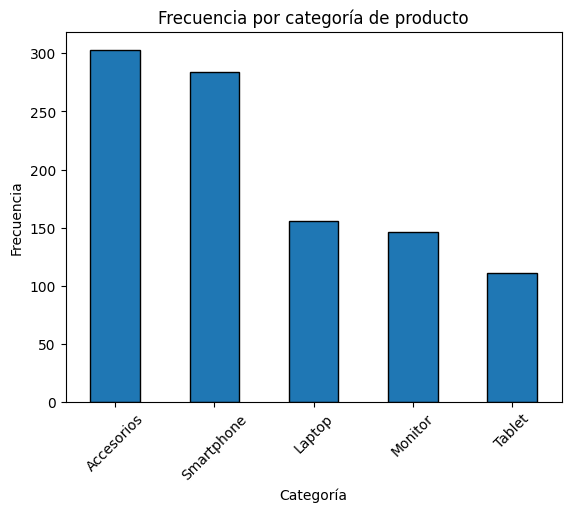

In [9]:
# Graficar la frecuencia por categoría de producto
frecuencia.plot(kind="bar", edgecolor="black")
plt.title("Frecuencia por categoría de producto")
plt.xlabel("Categoría")
plt.ylabel("Frecuencia")
plt.xticks(rotation=45)
plt.show()

**Interpretación:** Accesorios tiene más registros, con **303**, seguido de Smartphone, con **284**. Tablet tiene menos, con **111**.

**Cómo se lee el gráfico:** el eje horizontal muestra las categorías de producto y la altura de cada barra indica su cantidad de registros.

**Qué significan los resultados:** estas frecuencias incluyen los 1000 contactos, compren o no. Nos ayudan a ver qué productos aparecen más en los contactos, pero no indican qué categoría genera más ventas o ingresos.

## Actividad 2: Probabilidad

Estimar P(compra) con los 1000 contactos.

Calcular P(entrega puntual | compra) únicamente sobre compradores con información de entrega.

Comparar la conversión de al menos dos canales comerciales y explicar las diferencias.

In [10]:
# Estimar Probabilidad (compra) con los 1000 contactos.
prob_compra = df["realizo_compra"].mean()

print("Probabilidad(compra):", round(prob_compra, 4))
print("Porcentaje:", round(prob_compra * 100, 2),"%")

Probabilidad(compra): 0.763
Porcentaje: 76.3 %


In [11]:
# Calcular Probabilidad (entrega puntual | compra)
# únicamente sobre compradores con información de entrega
entregas = df[(df["realizo_compra"] == 1) & (df["entrega_puntual"].notna())]

prob_puntual = entregas["entrega_puntual"].mean()

print("P(entrega puntual | compra):", round(prob_puntual, 4))
print("Porcentaje:", round(prob_puntual * 100, 2), "%")

P(entrega puntual | compra): 0.7969
Porcentaje: 79.69 %


La probabilidad de compra observada es **0,763**, es decir, **76,3 %**: compraron 763 de los 1000 contactos. Esto nos indica que aproximadamente 76 de cada 100 contactos compraron en estos datos.

Entre los 763 compradores con información de entrega, **608 recibieron a tiempo**. La probabilidad de entrega puntual es **79,69 %**; las otras 155 entregas tuvieron retraso. No se cuenta a los contactos que no compraron como entregas tardías.

In [12]:
# Comparar la conversión de al menos dos canales comerciales y explicar las diferencias.
print("\nCanales:", df["canal"].unique())
conversion = df.groupby("canal")["realizo_compra"].mean() * 100
print(conversion.round(2))


Canales: ['WhatsApp' 'Tienda' 'Web']
canal
Tienda      76.24
Web         76.18
WhatsApp    76.65
Name: realizo_compra, dtype: float64


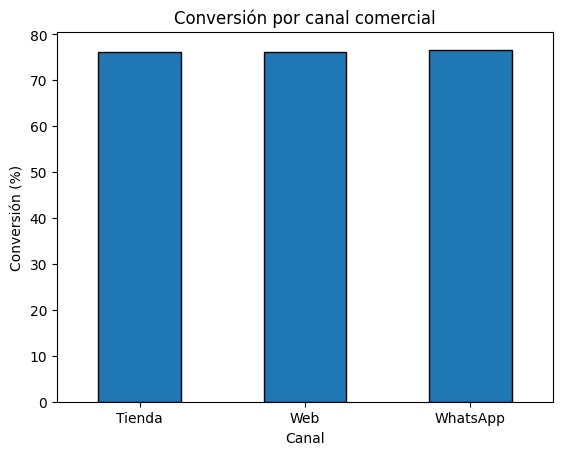

In [13]:
# Graficar la conversión por canal comercial
conversion.plot(kind="bar", edgecolor="black")
plt.title("Conversión por canal comercial")
plt.xlabel("Canal")
plt.ylabel("Conversión (%)")

plt.xticks(rotation=0)
plt.show()

**Interpretación:** WhatsApp tiene una conversión de **76,65 %**, Tienda de **76,24 %** y Web de **76,18 %**. La diferencia entre WhatsApp y Web es de aproximadamente **0,47 puntos porcentuales**, así que es pequeña.

**Cómo se lee el gráfico:** el eje horizontal muestra los canales comerciales y el eje vertical indica el porcentaje de contactos de cada canal que compraron.

**Qué significan los resultados:** los tres canales convierten de forma parecida. WhatsApp tiene el porcentaje más alto, pero recibió menos contactos: 197, frente a 361 de Web y 442 de Tienda. Las diferencias pueden deberse a los clientes o a la variación de los datos; este gráfico no prueba que el canal sea la causa. No conviene cambiar toda la inversión por una diferencia tan pequeña.

## Actividad 3: Distribución binomial y p-valor

Considerar como ensayos las entregas con puntualidad registrada.

Formular H0: p ≤ 0.70 frente a H1: p > 0.70.

Ejecutar una prueba binomial exacta unilateral con significancia α = 0.05.

Reportar n, entregas puntuales, proporción observada, p-valor y decisión.

Explicar los supuestos y limitaciones de independencia.

In [14]:
# Considerar como ensayos las entregas con puntualidad registrada.
datos_entrega = df["entrega_puntual"].dropna()

n = len(datos_entrega)
puntuales = int(datos_entrega.sum())
proporcion = puntuales / n

# Formular H0: p ≤ 0.70 frente a H1: p > 0.70.
# Ejecutar una prueba binomial exacta unilateral con significancia α = 0.05.
prueba = binomtest(puntuales, n, p=0.70, alternative="greater")
p_valor = prueba.pvalue

# Reportar n, entregas puntuales, proporción observada, p-valor y decisión.
print("n:", n)
print("Entregas puntuales:", puntuales)
print("Proporción observada:", round(proporcion, 4))
print("p-valor:", p_valor)

if p_valor < 0.05:
    print("Decisión: Se rechaza H0")
else:
    print("Decisión: No se rechaza H0")

n: 763
Entregas puntuales: 608
Proporción observada: 0.7969
p-valor: 9.203499451822028e-10
Decisión: Se rechaza H0


La proporción observada es **0,7969**: de las 763 entregas registradas, 608 fueron puntuales, aproximadamente el **79,69 %**.

El p-valor es aproximadamente **9,20 × 10⁻¹⁰**. Si la puntualidad real fuera del 70 %, sería muy poco probable obtener 608 o más entregas puntuales en 763 ensayos. Se usa el 70 % porque es el límite de H0 que da la mayor probabilidad de ese resultado o uno más extremo.

Como el p-valor es menor que **0,05**, se rechaza H0. En estos datos hay evidencia a favor de una puntualidad mayor al 70 %, bajo los supuestos de la prueba. El p-valor no es la probabilidad de que H0 sea verdadera: calcula la probabilidad de un resultado como este o más extremo suponiendo el valor de referencia de H0.

**Supuestos y limitaciones:** cada entrega debe tener dos resultados posibles, puntual o tardía, y se supone una misma probabilidad de puntualidad e independencia entre entregas. Esto puede no cumplirse si varias entregas comparten repartidor, ruta o día, porque un mismo problema podría retrasarlas juntas. Además, analizamos entregas registradas; no podemos asegurar que el resultado se mantenga en otros periodos.

## Actividad 4: Aprendizaje supervisado

Predecir realizo_compra con regresión logística usando edad, visitas_web,
contactos_comerciales, precio_cotizado_soles y descuento_porcentaje. Dividir en
entrenamiento (80 %) y prueba (20 %) de manera estratificada. Utilizar una canalización con
escalado y entrenar solo en los datos de entrenamiento. Presentar accuracy, matriz de
confusión y conclusiones.

In [15]:
# Predecir realizo_compra con las cinco variables indicadas.
X = df[["edad", "visitas_web", "contactos_comerciales",
        "precio_cotizado_soles", "descuento_porcentaje"]]
y = df["realizo_compra"]

# Dividir en entrenamiento (80 %) y prueba (20 %) de manera estratificada.
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Utilizar una canalización con escalado y entrenar solo con entrenamiento.
modelo = Pipeline([
    ("escalado", StandardScaler()),
    ("regresion", LogisticRegression())
])
modelo.fit(X_entrenamiento, y_entrenamiento)
prediccion = modelo.predict(X_prueba)

print("Registros de entrenamiento:", len(X_entrenamiento))
print("Registros de prueba:", len(X_prueba))

Registros de entrenamiento: 800
Registros de prueba: 200


Se usan **800 registros para entrenar** y **200 para probar**. La división estratificada mantiene una proporción parecida de compradores y no compradores en ambos conjuntos. La canalización aprende el escalado y el modelo solo con entrenamiento, para que los datos de prueba no influyan en ese aprendizaje.

Accuracy: 0.775
Porcentaje de aciertos: 77.5 %
Matriz de confusión (orden: no compra, compra):
[[  4  43]
 [  2 151]]


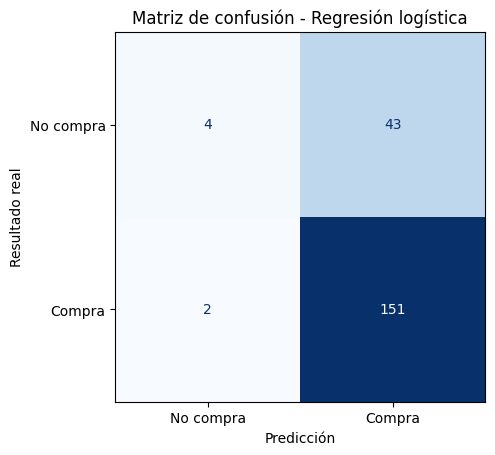

In [16]:
# Presentar accuracy, matriz de confusión y su gráfico.
accuracy = accuracy_score(y_prueba, prediccion)
matriz = confusion_matrix(y_prueba, prediccion, labels=[0, 1])

print("Accuracy:", round(accuracy, 4))
print("Porcentaje de aciertos:", round(accuracy * 100, 2), "%")
print("Matriz de confusión (orden: no compra, compra):")
print(matriz)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No compra", "Compra"]
).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusión - Regresión logística")
plt.xlabel("Predicción")
plt.ylabel("Resultado real")
plt.show()

**Interpretación:** el modelo acierta **155 de 200 casos**, con un accuracy de **77,5 %**.

**Cómo se lee el gráfico:** las filas muestran el resultado real y las columnas, la predicción. La diagonal contiene los aciertos: **4** casos de no compra y **151** de compra. Fuera de la diagonal hay **43** personas que no compraron, pero el modelo predijo compra, y **2** que compraron, pero el modelo predijo no compra.

**Qué significan los resultados:** el modelo predice compra en muchos casos y distingue poco a quienes no compran. Como hay más compradores, es necesario comparar este accuracy con un predictor base antes de decir que el modelo es útil.

In [17]:
# Comparar el modelo supervisado con un predictor base de clase mayoritaria.
clase_mayoritaria = y_entrenamiento.mode()[0]
prediccion_base = np.full(len(y_prueba), clase_mayoritaria)
accuracy_base = accuracy_score(y_prueba, prediccion_base)

print("Clase mayoritaria en entrenamiento:", clase_mayoritaria)
print("Accuracy del modelo:", round(accuracy, 4))
print("Accuracy del predictor base:", round(accuracy_base, 4))
print("Mejora en puntos porcentuales:", round((accuracy - accuracy_base) * 100, 2))

Clase mayoritaria en entrenamiento: 1
Accuracy del modelo: 0.775
Accuracy del predictor base: 0.765
Mejora en puntos porcentuales: 1.0


El predictor base siempre responde **compra**, porque esa es la clase mayoritaria en entrenamiento. Acierta **153 de los 200 casos de prueba**, con un accuracy de **76,5 %**.

La regresión logística llega al **77,5 %**, solo **1 punto porcentual** más: son dos aciertos adicionales. En este caso su utilidad es limitada, sobre todo para detectar a quienes no compran. No parece suficiente para tomar decisiones comerciales por sí sola; habría que comprobar si mantiene una mejora útil con nuevos datos.

## Actividad 5: Aprendizaje no supervisado

Aplicar K-Means a variables del comportamiento previo a la compra (p. ej., visitas_web,
contactos_comerciales y precio_cotizado_soles), escaladas. Probar k = 2 a 5, comparar
inercia y Silhouette Score, seleccionar k y describir los perfiles encontrados sin
interpretarlos como etiquetas reales.

In [18]:
# Aplicar escalado a las variables del comportamiento previo a la compra.
datos = df[["visitas_web", "contactos_comerciales", "precio_cotizado_soles"]]
escalador = StandardScaler()
datos_escalados = escalador.fit_transform(datos)

# Probar k = 2 a 5 y comparar inercia y Silhouette Score.
resultados = []

for k in range(2, 6):
    modelo_grupos = KMeans(n_clusters=k, random_state=42, n_init=10)
    grupos = modelo_grupos.fit_predict(datos_escalados)
    inercia = modelo_grupos.inertia_
    silhouette = silhouette_score(datos_escalados, grupos)
    resultados.append([k, inercia, silhouette])

resultados = pd.DataFrame(resultados, columns=["k", "Inercia", "Silhouette"])
resultados.round(4)

,k,Inercia,Silhouette
0,2,2236.6950,0.2661
1,3,1704.9595,0.2925
2,4,1312.5967,0.2923
3,5,1112.5872,0.2850


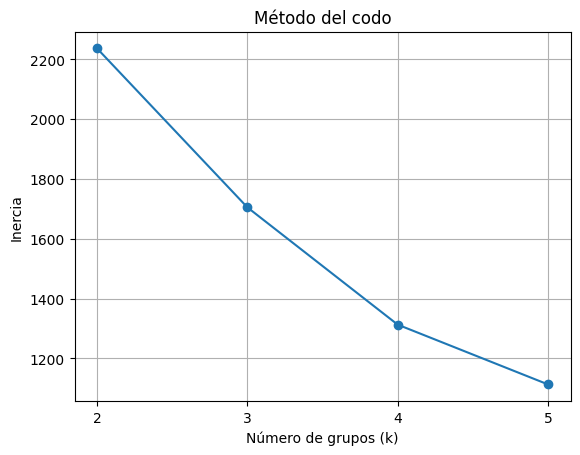

In [19]:
# Comparar la inercia con el gráfico del método del codo.
plt.plot(resultados["k"], resultados["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inercia")
plt.xticks([2, 3, 4, 5])
plt.grid()
plt.show()

**Interpretación:** la inercia baja de **2236,70** con dos grupos a **1112,59** con cinco grupos. La reducción se va haciendo más pequeña.

**Cómo se lee el gráfico:** el eje horizontal muestra la cantidad de grupos y el vertical, la suma de las distancias al cuadrado de los registros al centro de su grupo, usando las variables escaladas. Una inercia menor indica grupos más compactos.

**Qué significan los resultados:** añadir grupos reduce la inercia, pero aquí no hay un codo muy marcado. Por eso también revisamos el Silhouette Score antes de elegir k.

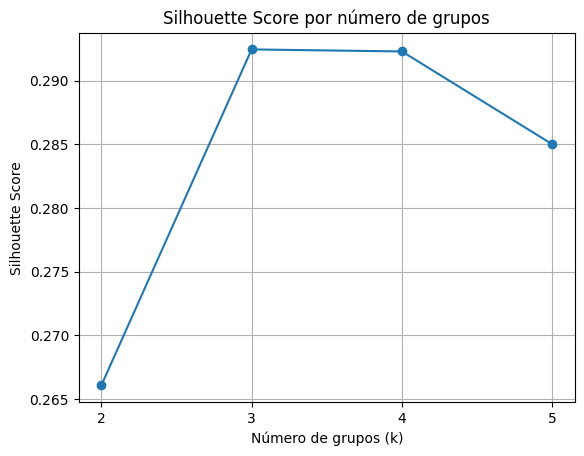

In [20]:
# Comparar el Silhouette Score para seleccionar el número de grupos.
plt.plot(resultados["k"], resultados["Silhouette"], marker="o")
plt.title("Silhouette Score por número de grupos")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Silhouette Score")
plt.xticks([2, 3, 4, 5])
plt.grid()
plt.show()

**Interpretación:** el mayor Silhouette Score se obtiene con **k = 3**, aproximadamente **0,2925**, aunque es casi igual al de **k = 4**, que es **0,2923**.

**Cómo se lee el gráfico:** el eje horizontal muestra k y el vertical indica qué tan bien queda cada registro dentro de su grupo frente a otros grupos, en promedio. Los valores van de −1 a 1; los valores más cercanos a 1 indican una mejor separación.

**Qué significan los resultados:** elegimos **3 grupos** porque tiene el mayor valor y permite describir menos grupos que k = 4, con un resultado casi igual. El valor cercano a 0,29 indica que los grupos no están claramente separados; no son tipos reales de clientes ni etiquetas definitivas.

In [21]:
# Seleccionar k = 3 y mostrar los promedios de las variables por grupo.
modelo_grupos = KMeans(n_clusters=3, random_state=42, n_init=10)
grupos = modelo_grupos.fit_predict(datos_escalados)

datos_grupos = datos.copy()
datos_grupos["grupo"] = grupos
promedios = datos_grupos.groupby("grupo")[[
    "visitas_web", "contactos_comerciales", "precio_cotizado_soles"
]].mean()
promedios.round(2)

,visitas_web,contactos_comerciales,precio_cotizado_soles
grupo,,,
0,4.83,4.05,2772.87
1,5.16,6.11,745.06
2,5.06,2.52,773.30


**Perfiles encontrados**

- **Grupo 0:** tiene unas **4,83 visitas**, **4,05 contactos comerciales** y una cotización promedio de **S/ 2772,87**. Se diferencia principalmente por las cotizaciones más altas.
- **Grupo 1:** tiene unas **5,16 visitas**, **6,11 contactos comerciales** y una cotización promedio de **S/ 745,06**. Tiene más contactos comerciales que los otros grupos.
- **Grupo 2:** tiene unas **5,06 visitas**, **2,52 contactos comerciales** y una cotización promedio de **S/ 773,30**. Tiene menos contactos comerciales y cotizaciones parecidas a las del grupo 1.

Estos son promedios: ningún cliente necesita tener exactamente esos valores. Los números 0, 1 y 2 solo identifican agrupaciones; no indican un orden de importancia ni permiten asegurar quién comprará.

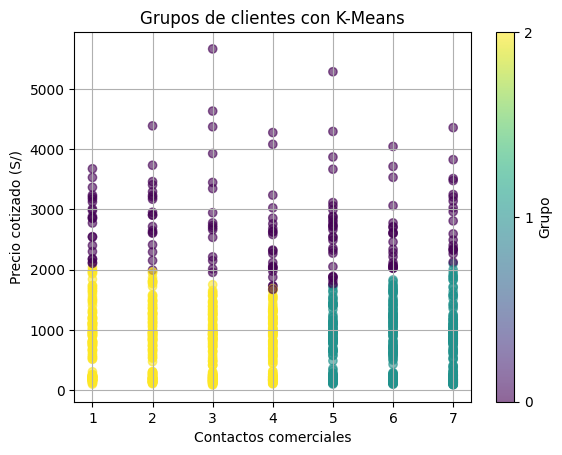

In [22]:
# Mostrar los grupos según contactos comerciales y precio cotizado.
plt.scatter(datos_grupos["contactos_comerciales"],
            datos_grupos["precio_cotizado_soles"],
            c=datos_grupos["grupo"], cmap="viridis", alpha=0.6)
plt.title("Grupos de clientes con K-Means")
plt.xlabel("Contactos comerciales")
plt.ylabel("Precio cotizado (S/)")
plt.colorbar(ticks=[0, 1, 2], label="Grupo")
plt.grid()
plt.show()

**Interpretación:** el grupo 0 reúne principalmente cotizaciones altas. Entre las cotizaciones más bajas, el grupo 1 suele tener más contactos comerciales que el grupo 2.

**Cómo se lee el gráfico:** cada punto representa un contacto del dataset. El eje horizontal muestra sus contactos comerciales, el vertical muestra su precio cotizado en soles y el color identifica el grupo asignado.

**Qué significan los resultados:** los grupos pueden orientar seguimientos distintos, pero hay puntos que se superponen. El modelo también usó visitas_web, que no aparece en este gráfico de dos ejes. Los colores representan agrupaciones calculadas, no categorías reales ni resultados de compra.

## Evidencias y preguntas de análisis

### 1. Entregar notebook ejecutable con código, resultados, gráficos y explicaciones.

Este notebook incluye el desarrollo de las cinco actividades, sus resultados y las interpretaciones. Se ejecuta de arriba hacia abajo con el CSV indicado.

### 2. Interpretar al menos tres métricas estadísticas con sus unidades.

La **media de S/ 913,95** es el monto promedio por compra. La **mediana de S/ 798,36** divide las compras en dos mitades según su monto. La **desviación estándar de S/ 769,12** indica bastante variación entre los montos. La **varianza de 591 538,57 soles²** también mide esa variación, pero en unidades al cuadrado.

### 3. ¿Qué conclusión comercial permite obtener la probabilidad de conversión?

El **76,3 %** de los contactos compró. Si llegan contactos parecidos y se mantienen las condiciones, esta proporción puede servir como referencia para planificar la atención y las ventas, sin garantizar el resultado futuro. Los tres canales tienen conversiones parecidas, así que no conviene priorizar uno solo por esas pequeñas diferencias.

### 4. ¿Qué significa el p-valor obtenido y por qué no es la probabilidad de que H0 sea verdadera?

El p-valor de aproximadamente **9,20 × 10⁻¹⁰** indica que, con una puntualidad real del 70 % y bajo los supuestos de la prueba, sería muy poco probable observar 608 o más entregas puntuales de 763. Como es menor que 0,05, rechazamos H0. No mide la probabilidad de H0; mide la probabilidad de ese resultado o uno más extremo suponiendo el valor de referencia de H0.

### 5. Comparar el modelo supervisado con un predictor base y justificar si resulta útil.

La regresión logística tiene **77,5 %** de accuracy y el predictor que siempre dice compra tiene **76,5 %**. La mejora es de solo **1 punto porcentual**, equivalente a dos aciertos más en 200 casos. Su utilidad es limitada en esta prueba, especialmente porque se equivoca en 43 de los 47 casos de no compra.

### 6. Describir los segmentos de K-Means y proponer cinco mejoras para la empresa.

Con k = 3 aparece un grupo de cotizaciones altas, otro de cotizaciones más bajas con más contactos comerciales y otro de cotizaciones más bajas con menos contactos. Son agrupaciones aproximadas de estos datos y no etiquetas reales de los clientes.

**Cinco mejoras para la empresa:**

1. **Revisar los retrasos de entrega:** registrar sus motivos y revisar rutas y horarios, ya que 155 de las 763 entregas no fueron puntuales.
2. **Cuidar la atención en los tres canales:** como sus conversiones son parecidas, comparar también el costo de atender cada contacto antes de cambiar la inversión.
3. **Dar asesoría a las cotizaciones altas:** probar una atención más personalizada para el perfil del grupo 0 y comprobar si ayuda a cerrar compras.
4. **Ajustar el seguimiento comercial:** revisar si los contactos repetidos del perfil del grupo 1 ayudan y probar recordatorios oportunos para el perfil del grupo 2, sin asumir que más contactos causan más compras.
5. **Mejorar los datos para predecir compras:** registrar motivos de no compra y calidad de la atención, y probar de nuevo el modelo con datos posteriores antes de usarlo para priorizar clientes.

## Conclusión general

En los 1000 contactos, **763 realizaron una compra**, por lo que la conversión fue de **76,3 %**. Los canales tuvieron resultados muy parecidos. Las compras tuvieron un promedio de **S/ 913,95** y una mediana de **S/ 798,36**; hay diferencias grandes entre los montos vendidos.

La puntualidad fue de **79,69 %**. La prueba binomial permite rechazar H0 y respalda una puntualidad mayor al 70 %, siempre considerando sus supuestos. Aun así, quedan **155 entregas tardías** que la empresa debería revisar.

La regresión logística acertó el **77,5 %**, frente al **76,5 %** del predictor base. La mejora es pequeña, así que no basta para confiarle decisiones comerciales por sí sola. K-Means permitió describir **tres grupos** según cotizaciones y comportamiento previo a la compra, aunque no están muy separados. En este caso pueden servir para probar formas distintas de seguimiento y revisar si ayudan a mejorar las ventas y la atención.